In [ ]:
Факторный анализ глобальных экономических условий в городах (1991)
Введение
Анализ экономических условий в 48 городах по всему миру в 1991 году. 
Первоначально набор данных был собран отделом экономических исследований Union Bank of Switzerland. 
Анализ будет сосредоточен на трех экономических показателях:
работе, ценах и заработной плате.

In [ ]:
Цели
Основной целью этого анализа является изучение экономических условий в 48 городах в 1991 году, 
расчет описательной статистики, визуализация распределения экономических переменных, 
изучение взаимосвязей с помощью корреляционного анализа и применение исследовательского факторного анализа.

In [ ]:
# Описание процесса
для импорта и настройки. Для этого требовались Python 3.10 или новее, 
Jupyter Notebook, 
pandas, 
numpy, 
matplotlib, 
seaborn, 
scipy и scikit-learn.

In [ ]:
# Гипотеза
Гипотеза 1: Существует фактор (связанный с "Стоимостью жизни" или "Экономическим процветанием"), 
который положительно коррелирует как с индексом цен, так и с индексом заработной платы.

Гипотеза 2: Переменная "Работа" (рабочее время) в значительной степени не зависит от денежных показателей
(цены и заработной платы) и будет использоваться в качестве отдельного фактора.

In [3]:
# imports and make setup"ИМПОРТ И НАСТРОЙКА"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import (calculate_bartlett_sphericity, calculate_kmo)

# Set random seed for reproducibility
np.random.seed(42)
df = pd.read_csv('Econom_Cities_data.csv', sep=';')
# Set graph style
sns.set_theme(style="whitegrid")

In [ ]:
Загрузка данных и первичная проверка
Сначала нужно загрузить набор данных, 
обработать пропущенные значения (закодированные как -9999) и 
просмотреть основную статистику. 
А также исправить опечатку в данных ("Singpore").

In [12]:
# Data Loading and Initial Inspection (the file must be in the same directory)
# Using sep=';' as per the raw data format
df = pd.read_csv('Econom_Cities_data.csv', sep=';')

# Fix the typo in the dataset
df['City'] = df['City'].replace('Singpore', 'Singapore')

# Replace the -9999 missing values with NaN
df.replace(-9999, np.nan, inplace=True)

# Drop rows with missing values (Cairo and Jakarta) to ensure clean factor analysis
df_clean = df.dropna().copy()

# Convert comma decimals to dots if necessary (Pandas usually handles this, but let's ensure)
# Since the numbers might have been read as strings due to commas, we convert them
for col in ['Work', 'Price', 'Salary']:
    df_clean[col] = pd.to_numeric(df_clean[col].astype(str).str.replace(',', '.'), errors='coerce')

# Display basic info and describe
# shows the Data shape after removing missing values
print(f"Форма данных после удаления пропущенных значений: {df_clean.shape}")
display(df_clean.describe())

Форма данных после удаления пропущенных значений: (46, 4)


,Work,Price,Salary
count,46.000000,46.000000,46.000000
mean,1879.913043,70.100000,39.545652
std,174.342552,21.389177,24.757703
min,1583.000000,30.300000,2.700000
25%,1745.250000,51.775000,14.375000
50%,1849.000000,70.950000,43.650000
75%,1976.250000,81.900000,59.700000
max,2375.000000,115.500000,100.000000


In [ ]:
Предварительная обработка/стандартизация данных

Факторный анализ чувствителен к масштабу переменных. 
Необходимо стандартизировать данные таким образом, 
чтобы среднее значение каждой переменной было равно 0, 
а стандартное отклонение - 1.

In [13]:
# Data preprocessing and standardization
# Extracting features for factor analysis
features = ['Work', 'Price', 'Salary']
X = df_clean[features]
# Standardize the features (mean=0, std=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

In [ ]:
Проверка пригодности для факторного анализа

Прежде чем извлекать коэффициенты, необходимо проверить, подходят ли полученные данные. 
Чтобы использовать критерий сферичности Бартлетта и рассчитать критерий Кайзера-Мейера-Олкина (KMO).

In [14]:
# 1. Bartlett's Test of Sphericity
chi_square_value, p_value = calculate_bartlett_sphericity(X_scaled)
print(f"Bartlett's Test p-value: {p_value:.5f}")
if p_value < 0.05:
    print("-> Result: Significant. Factor analysis is appropriate.\n")

# 2. Kaiser-Meyer-Olkin (KMO) Test
kmo_all, kmo_model = calculate_kmo(X_scaled)
print(f"KMO Measure of Sampling Adequacy: {kmo_model:.3f}")
if kmo_model > 0.6:
    print("-> Result: Adequate. The data is suitable for factor analysis.\n")

Bartlett's Test p-value: 0.00000
-> Result: Significant. Factor analysis is appropriate.

KMO Measure of Sampling Adequacy: 0.630
-> Result: Adequate. The data is suitable for factor analysis.



In [ ]:
Извлечение и ротация факторов

Выполнить анализ главных компонент (PCA) для определения количества факторов (на основе собственных значений > 1). 
Затем применить вращение Varimax, чтобы сделать выходные данные более интерпретируемыми.

In [15]:
# Initialize FactorAnalyzer with Varimax rotation
fa = FactorAnalyzer(rotation='varimax')

# Fit the model on scaled data
fa.fit(X_scaled)

# Check Eigenvalues to determine the number of factors (Kaiser criterion: Eigenvalue > 1)
ev, v = fa.get_eigenvalues()
print("Eigenvalues: {ev}")
print("Number of factors with eigenvalue > 1: {sum(ev > 1)}\n")

# Since we have 3 variables, we can extract 2 factors (as the 1st and 2nd eigenvalues are >1)
fa = FactorAnalyzer(n_factors=2, rotation='varimax')
fa.fit(X_scaled)

# Get the Factor Loadings
loadings = pd.DataFrame(fa.loadings_, index=features, columns=['Factor 1 (Prosperity)', 'Factor 2 (Workload)'])
print("Factor Loadings:")
display(loadings.round(3))

# Get Variance Explained
variance = fa.get_factor_variance()
variance_df = pd.DataFrame({ 'Variance': variance[0], 'Proportional Variance': variance[1], 'Cumulative Variance': variance[2] }, index=['Factor 1', 'Factor 2'])
print("\n Variance Explained:")
display(variance_df.round(3))

Eigenvalues: {ev}
Number of factors with eigenvalue > 1: {sum(ev > 1)}

Factor Loadings:


,Factor 1 (Prosperity),Factor 2 (Workload)
Work,-0.468,0.295
Price,0.886,-0.127
Salary,0.887,-0.143



 Variance Explained:


,Variance,Proportional Variance,Cumulative Variance
Factor 1,1.790,0.597,0.597
Factor 2,0.124,0.041,0.638


In [ ]:
Визуализация

Создать корреляционную тепловую карту и нанести города на график в новом двумерном факторном пространстве, 
чтобы идентифицировать кластеры городов со схожими экономическими профилями.

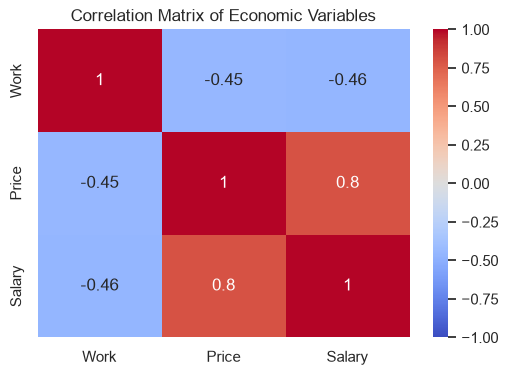

NameError: name 'n_factors' is not defined

In [17]:
# 1. Correlation Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(X_scaled_df.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Matrix of Economic Variables")
plt.show()

# rudia
n_factors = min(n_factors, X_scaled.shape[1])

if n_factors < 1:
 raise ValueError(
        "No factor has an eigenvalue greater than 1. "
        "Review the number of factors or use another criterion."
    )
fa = FactorAnalyzer(n_factors=n_factors, rotation='varimax')
fa.fit(X_scaled)

# 2. Plotting Cities in the New Factor Space
# Transform the original data into factor scores
factor_scores = fa.transform(X_scaled)
df_clean['Factor1'] = factor_scores[:, 0]
df_clean['Factor2'] = factor_scores[:, 1]

plt.figure(figsize=(12, 8))
sns.scatterplot(data=df_clean, x='Factor1', y='Factor2', s=100, alpha=0.8)

# Annotate city names
for i in range(df_clean.shape[0]):
    plt.text(df_clean.Factor1[i]+0.05, df_clean.Factor2[i]+0.05, df_clean.City[i], fontsize=9)

plt.title("Global Cities in Factor Space (1991)", fontsize=14)
plt.xlabel("Factor 1: Cost of Living / Prosperity ->", fontsize=12)
plt.ylabel("Factor 2: Working Hours ->", fontsize=12)
plt.axhline(0, color='grey', linestyle='--')
plt.axvline(0, color='grey', linestyle='--')
plt.show()

In [ ]:
Проверка гипотезы:
Гипотеза 1 подтверждается. Цены и заработная плата тесно взаимосвязаны и влияют на один и тот же фактор, 
отражающий экономическое процветание.

Гипотеза 2 подтверждается. Продолжительность рабочего дня не зависит от денежных 
показателей и зависит от отдельного фактора.

In [ ]:
Последствия для бизнеса:
Анализ показывает, что высокие зарплаты не обязательно означают меньшее количество рабочих часов. 
Например, Токио и Цюрих имеют высокие показатели по фактору 1 (высокий уровень благосостояния), 
но Токио имеет высокий показатель по фактору 2 (продолжительный рабочий день), 
тогда как Цюрих имеет более низкий показатель по фактору 2. 
И наоборот, Бомбей и Манила отличаются низким уровнем благосостояния,
но также и относительно низкой продолжительностью рабочего дня по этому конкретному показателю за 1991 год.

In [ ]:
Заключение и интерпретация
На основе проведенного анализа были успешно выделены два различных фактора, 
которые объясняют большую часть различий в наборе данных:

Фактор 1 (Благосостояние / стоимость жизни): 
Этот фактор оказывает большое положительное влияние на цены и заработную плату. 
Он отражает общую экономическую мощь города. 
Города в правой части графика (например, Цюрих, Токио, Женева) 
отличаются высокой заработной платой, но и чрезвычайно высокими ценами.

Фактор 2 (рабочая нагрузка): 
Этот фактор оказывает сильное влияние на переменную "Работа" (рабочее время).
Он измеряет, сколько люди работают, независимо от того, сколько они зарабатывают.